
# Tutorial: Constructing and Solving a Picket-Fence Model Hamiltonian

## What this tutorial covers

**In this tutorial, we:**
    
**- construct a model Hamiltonian using the ModelHamiltonian package**
    
**- generate one- and two-body integrals**
    
**- solve the system using Full Configuration Interaction (FCI)**
    
**- analyze how the ground state energy scales with system size**
    
**This workflow reflects the typical pipeline used in model Hamiltonian studies.**

**The picket-fence model consists of equally spaced energy levels with pairing interactions between fermions.**
**Despite its simplicity, it captures key features of many-body quantum systems and is often used as a benchmark model.**


In [ ]:
# import libraries
import numpy as np
from moha import HamHeisenberg
from pyscf import fci

In [30]:
def compute_energy(L, J_eq, J_ax, mu):
    connectivity = np.zeros((L, L))
    connectivity[np.arange(L-1), np.arange(L-1)+1] = 1
    connectivity[0, -1] = 1
    connectivity += connectivity.T

    ham = HamHeisenberg(connectivity=connectivity, J_eq=J_eq, J_ax=J_ax, mu=mu)

    e0 = ham.generate_zero_body_integral()
    h1 = ham.generate_one_body_integral(dense=True, basis='spatial basis')
    h2 = ham.generate_two_body_integral(dense=True, basis='spatial basis', sym=4)

    h2_ch = np.transpose(h2, (0, 2, 1, 3))
    e, _ = fci.direct_spin0.kernel(h1, h2_ch, L, L)

    return (e + e0) / L

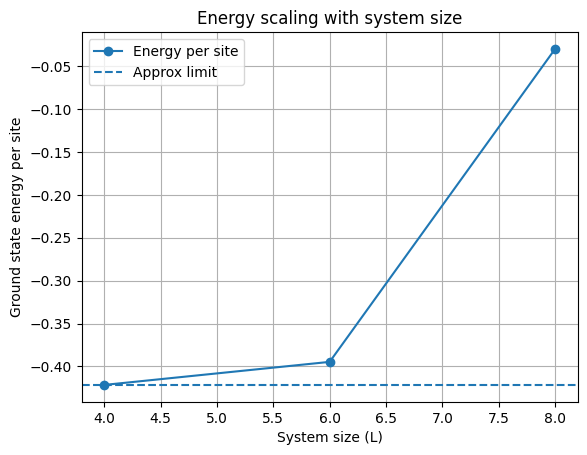

In [31]:
import matplotlib.pyplot as plt

# Store results
L_values = [4, 6, 8]
energies = []

for L in L_values:
    connectivity = np.zeros((L, L))
    connectivity[np.arange(L-1), np.arange(L-1)+1] = 1
    connectivity[0, -1] = 1
    connectivity += connectivity.T

    ham = HamHeisenberg(connectivity=connectivity, J_eq=J_eq, J_ax=J_ax, mu=mu)

    e0 = ham.generate_zero_body_integral()
    h1 = ham.generate_one_body_integral(dense=True, basis='spatial basis')
    h2 = ham.generate_two_body_integral(dense=True, basis='spatial basis', sym=4)

    h2_ch = np.transpose(h2, (0, 2, 1, 3))
    e, _ = fci.direct_spin0.kernel(h1, h2_ch, L, L)

    energy_per_site = compute_energy(L, J_eq, J_ax, mu)
    energies.append(energy_per_site)

# Plot results
plt.figure()
plt.plot(L_values, energies, 'o-', label='Energy per site')


plt.axhline(y=min(energies), linestyle='--', label='Approx limit')
plt.legend()

plt.xlabel("System size (L)")
plt.ylabel("Ground state energy per site")
plt.title("Energy scaling with system size")
plt.grid()

plt.show()

In [34]:
print(f"Approximate ground state energy (per site): {min(energies):.6f}")

Approximate ground state energy (per site): -0.421535


In [33]:
# Effect of interaction strength (J_eq)
print("Effect of interaction strength:")

for g in [0.5, 1.0, 1.5]:
    energy = compute_energy(6, g, g/2, mu)
    print(f"J_eq={g}, energy per site={energy:.6f}")

Effect of interaction strength:
J_eq=0.5, energy per site=-0.197336
J_eq=1.0, energy per site=-0.394672
J_eq=1.5, energy per site=-0.592008


### Effect of interaction strength

**We explore how the interaction strength affects the ground state energy.**
**We explore how the interaction strength affects the ground state energy.
Increasing the coupling strength leads to a lower energy, indicating stronger
correlations in the system and highlighting the role of interactions in determining
the system's behavior.**

### Remarks

**The system sizes considered here are small due to the exponential scaling of FCI.**
**For larger systems, approximate methods would be required.**